# 04c — Validación de supuestos: modelo IV (2SLS)

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 4c — Validación del modelo de la Fase 3c (elasticidad IV con controles = -0.8414)

A diferencia de OLS y panel FE, el diagnóstico central de un modelo IV no
es heterocedasticidad/normalidad (aunque también se revisan), sino:
¿la variable instrumentada realmente *era* endógena?, ¿los instrumentos
son suficientemente fuertes? (ya visto en 03c), ¿son válidos? (Hansen J,
ya visto y rechazado en 03c).

Objetivos:
1. Test formal de endogeneidad (Durbin-Wu-Hausman / Wooldridge) -- en vez
   de solo "ver a ojo" que OLS y 2SLS difieren
2. Inspección de residuos del modelo 2SLS
3. Síntesis de todos los diagnósticos de identificación (relevancia,
   validez, endogeneidad) en un solo lugar


In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from modeling import construir_instrumentos, modelo_iv_2sls
pd.set_option('display.max_columns', None)

## 1. Cargar datos y reajustar el modelo IV

In [2]:
df = pd.read_csv('../data/processed/demanda_limpia.csv')
df_instrumentado = construir_instrumentos(df)
resultado_iv, df_iv_usado = modelo_iv_2sls(df_instrumentado)
print('Modelo reajustado. Elasticidad IV:', resultado_iv.params['log_checkout_price'])

Modelo reajustado. Elasticidad IV: -0.8413792355003125


## 2. Test formal de endogeneidad (Durbin-Wu-Hausman)

**Qué hace:** compara formalmente el estimador OLS contra el estimador IV.
Si ambos son estadísticamente similares, no hay evidencia de que la
endogeneidad esté sesgando el OLS -- en ese caso, OLS sería preferible
(más eficiente). Si difieren significativamente, es evidencia de que
`log_checkout_price` sí es endógeno y el IV es necesario.

**H0:** la variable instrumentada (`log_checkout_price`) es exógena
(no hay diferencia sistemática entre OLS e IV).

In [3]:
print(resultado_iv.wu_hausman())
print()
print(resultado_iv.wooldridge_regression)

Wu-Hausman test of exogeneity
H0: All endogenous variables are exogenous
Statistic: 3715.1494
P-value: 0.0000
Distributed: F(1,456523)



Wooldridge's regression test of exogeneity
H0: Endogenous variables are exogenous
Statistic: 2565.1981
P-value: 0.0000
Distributed: chi2(1)


**Lectura:** con la especificación con controles, Wu-Hausman (F ≈ 3715) y el test de
Wooldridge (versión de regresión ≈ 2565, impresa arriba; versión *score* ≈ 1786, la reportada en el informe) rechazan la exogeneidad de `log_checkout_price`. El rechazo con N = 456 544 no
mide la magnitud del sesgo: la diferencia puntual OLS (-0.759) vs. 2SLS (-0.841) no es
estadísticamente distinguible con EE agrupados (IC IV [-0.940, -0.743]).

## 3. Residuos del modelo 2SLS

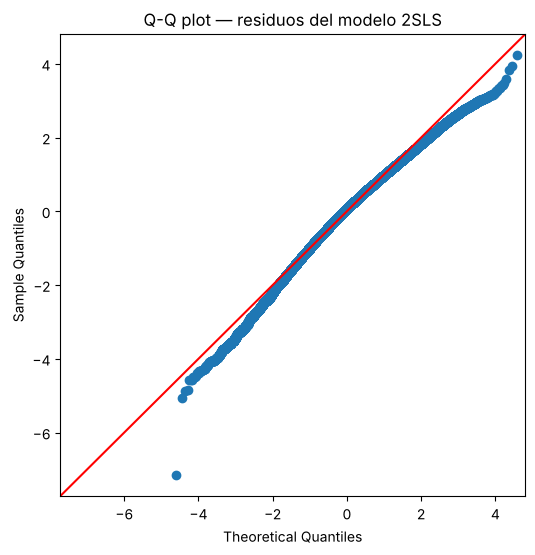

In [4]:
residuos_iv = resultado_iv.resids
fig = sm.qqplot(np.asarray(residuos_iv), line='45', fit=True)
fig.set_size_inches(6, 6)
plt.title('Q-Q plot — residuos del modelo 2SLS')
plt.savefig('../reports/notebook_outputs/qq_iv_2sls.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Síntesis de diagnósticos de identificación

| Diagnóstico | Pregunta | Resultado |
|---|---|---|
| Primera etapa | ¿instrumentos relevantes? | R² parcial de Shea 0.9226; F agrupado ≈ 2.2e5 — sin instrumento débil |
| Hansen J | ¿restricción de sobreidentificación? | 33.3 con ponderación HC; 0.92 (p = 0.34) con ponderación agrupada |
| Wu-Hausman / Wooldridge | ¿era necesario instrumentar? | Rechazan exogeneidad |

Ningún test valida la exclusión: ambos instrumentos podrían violarla de la misma forma, por lo que
el IV se presenta como análisis de sensibilidad.